# 04 · Perception data for any scenario

`av-world export-perception` simulates a scenario, renders six cameras (nuScenes' layout) around chosen AVs, and writes the 3-D
ground truth of everything around them plus what a sensor model reports (with misses behind occluders, position noise and ghost
detections). The folder is nuScenes-*style*: per-sample JSON, PNG images and calibration matrices any framework can read.

Rendering needs `pyvista` (`pip install pyvista`; it renders offscreen on a CPU). This notebook takes ~2 minutes.

[Website](https://haggler3.github.io/av_world/) · [All notebooks](README.md) · [README](../README.md)

In [1]:
%matplotlib inline
import os, subprocess, sys
def _repo():  # this notebook inside a clone of the repository, or anywhere else (Colab): fetch it
    p = os.path.abspath("")
    while p != os.path.dirname(p):
        if os.path.exists(os.path.join(p, "xnet", "sim.py")):
            return p
        p = os.path.dirname(p)
    if not os.path.exists("av_world"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/haggler3/av_world"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "av_world"], check=True)
    return os.path.abspath("av_world")
os.chdir(_repo()); sys.path.insert(0, os.getcwd())
import time
import numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
import av_world
print("av_world", av_world.__version__, "in", os.getcwd())
try:
    import pyvista  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyvista"], check=True)
import vtk
vtk.vtkLogger.SetStderrVerbosity(vtk.vtkLogger.VERBOSITY_OFF)   # silence VTK's display probing; it renders offscreen

av_world 0.4.0 in /home/user/av_world


## Pick a scenario

The famous-incident archetypes of `avlab.famous` (each sets the world up so the incident's pattern recurs), or `None` for
everyday traffic.

In [2]:
from avlab import famous
for name, (desc, *_ ) in famous.SCENARIOS.items():
    print(f"  {name:26s} {desc[:110]}")

  jaywalker_misclassified    a pedestrian crosses outside the signal phase and the AV's perception drops out while it approaches
  bus_dartout                a pedestrian steps out from in front of a stopped bus or van where cars cannot see
  stalled_vehicle_missed     a vehicle is stopped in the lane and the AV's sensor drops it from view while closing
  phantom_braking            the AV brakes hard for an obstacle that is not there while traffic follows
  sun_glare_blackout         the AV's sensors are blinded for a second or two at a time
  aggressive_cut_in          drivers squeeze into a gap far smaller than normal right in front of the AV
  red_light_runner           many drivers run the red and enter the junction at speed
  unprotected_left           drivers turn across oncoming traffic without looking
  cyclist_close_pass         many cyclists, and aggressive overtakers who clip them
  black_ice                  the road is slippery: braking distances double


## Export

10 simulated seconds around one AV in Chicago with buses pulling out from stops, at the default 176 x 96 pixels per camera. The
same from a shell: `av-world export-perception out --area chicago --scenario bus_dartout --seconds 10 --egos 1`.

In [3]:
from bev import export
t = time.time()
info = export.export("results/notebooks/perception_bus_dartout", area="chicago", scenario="bus_dartout", seconds=10, egos=1)
print(info, f"{time.time() - t:.0f} s")
OUT = info["out"]
print(sorted(os.listdir(OUT)))

{'out': 'results/notebooks/perception_bus_dartout', 'samples': 25, 'boxes': 201, 'sensor_detections': 178, 'cameras': 6, 'area': 'chicago', 'scenario': 'bus_dartout'} 27 s
['CAM_BACK', 'CAM_BACK_LEFT', 'CAM_BACK_RIGHT', 'CAM_FRONT', 'CAM_FRONT_LEFT', 'CAM_FRONT_RIGHT', 'calibration.json', 'data.npz', 'meta.json', 'samples.json', 'scene.json']


## What is in a sample

In [4]:
import json
samples = json.load(open(f"{OUT}/samples.json"))
cal = json.load(open(f"{OUT}/calibration.json"))
s = max(samples, key=lambda s: len(s["boxes"]))              # the busiest sample
print({k: v for k, v in s.items() if k not in ("boxes", "detections", "images")})
print("images:", s["images"])
print(f"{len(s['boxes'])} ground-truth boxes, e.g.", s["boxes"][0])
print(f"{len(s['detections'])} sensor detections, e.g.", s["detections"][0] if s["detections"] else None)
print("calibration of CAM_FRONT:", {k: cal["CAM_FRONT"][k] for k in ("width", "height", "yaw_deg", "hfov_deg")})

{'token': 'chicago_bus_dartout_s0_000002', 'timestamp_s': 0.8, 'ego_id': 360, 'sequence': 0, 'ego_pose_world': [78.63, 597.17, -1.498]}
images: {'CAM_FRONT': 'CAM_FRONT/000002.png', 'CAM_FRONT_LEFT': 'CAM_FRONT_LEFT/000002.png', 'CAM_FRONT_RIGHT': 'CAM_FRONT_RIGHT/000002.png', 'CAM_BACK': 'CAM_BACK/000002.png', 'CAM_BACK_LEFT': 'CAM_BACK_LEFT/000002.png', 'CAM_BACK_RIGHT': 'CAM_BACK_RIGHT/000002.png'}
10 ground-truth boxes, e.g. {'class': 'truck', 'center': [-0.152, 7.541, 1.237], 'size': [7.0, 2.05, 2.475], 'yaw': 0.752, 'velocity': [4.857, 4.543], 'occluded': False}
7 sensor detections, e.g. {'class': 'van', 'true_id': 10, 'center_xy': [85.94, 597.76], 'world_frame': True, 'center_ego_xy': [-0.06, 7.33]}
calibration of CAM_FRONT: {'width': 176, 'height': 96, 'yaw_deg': 0.0, 'hfov_deg': 70.0}


## The six cameras with the 3-D boxes projected

`ego2img` (BEVFormer's `lidar2img`) maps an ego-frame point to pixels. Boxes of objects hidden behind others are dashed.

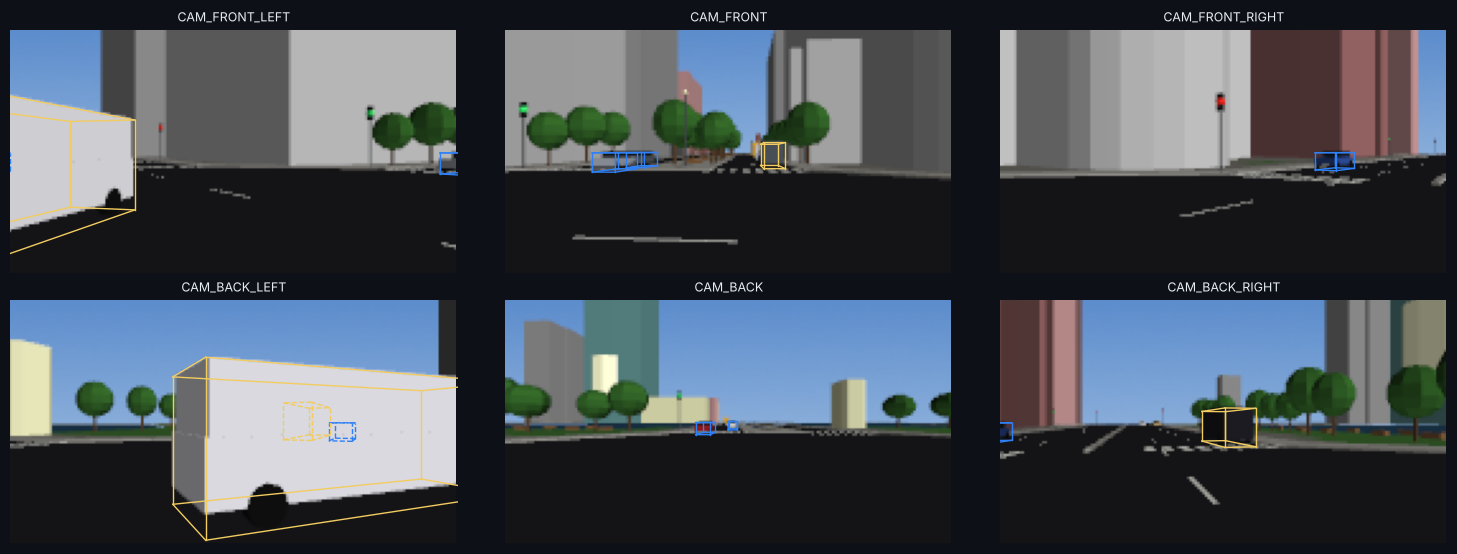

In [5]:
from PIL import Image as PILImage
from bev.rig import box_corners
COL = {"car": "#2f81f7", "truck": "#f2cc60", "bus": "#f2cc60", "bike": "#3fb950", "ped": "#f778ba"}
EDGES = [(0, 1), (1, 2), (2, 3), (3, 0), (4, 5), (5, 6), (6, 7), (7, 4), (0, 4), (1, 5), (2, 6), (3, 7)]
order = ["CAM_FRONT_LEFT", "CAM_FRONT", "CAM_FRONT_RIGHT", "CAM_BACK_LEFT", "CAM_BACK", "CAM_BACK_RIGHT"]
fig, axs = plt.subplots(2, 3, figsize=(15, 5.6), facecolor="#0d1117")
for ax, cam in zip(axs.ravel(), order):
    ax.imshow(PILImage.open(f"{OUT}/{s['images'][cam]}"))
    M, W, H = np.array(cal[cam]["ego2img"]), cal[cam]["width"], cal[cam]["height"]
    for b in s["boxes"]:
        c = box_corners(b["center"] + b["size"] + [b["yaw"]])
        q = np.c_[c, np.ones(8)] @ M.T
        if (q[:, 2] < 0.5).any():
            continue
        uv = q[:, :2] / q[:, 2:3]
        if uv[:, 0].max() < 0 or uv[:, 0].min() > W or uv[:, 1].max() < 0 or uv[:, 1].min() > H:
            continue
        for i, j in EDGES:
            ax.plot(uv[[i, j], 0], uv[[i, j], 1], color=COL.get(b["class"], "w"), lw=1, ls="--" if b["occluded"] else "-")
    ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.axis("off"); ax.set_title(cam, color="#e6edf3", fontsize=9)
fig.tight_layout(); display(fig); plt.close(fig)

## Bird's-eye view: ground truth against the sensor model

Boxes are the ground truth in the ego frame (x forward, y left); dots are what the sensor reported. Missing dots are misses
(mostly the occluded, dashed boxes); red crosses are ghosts.

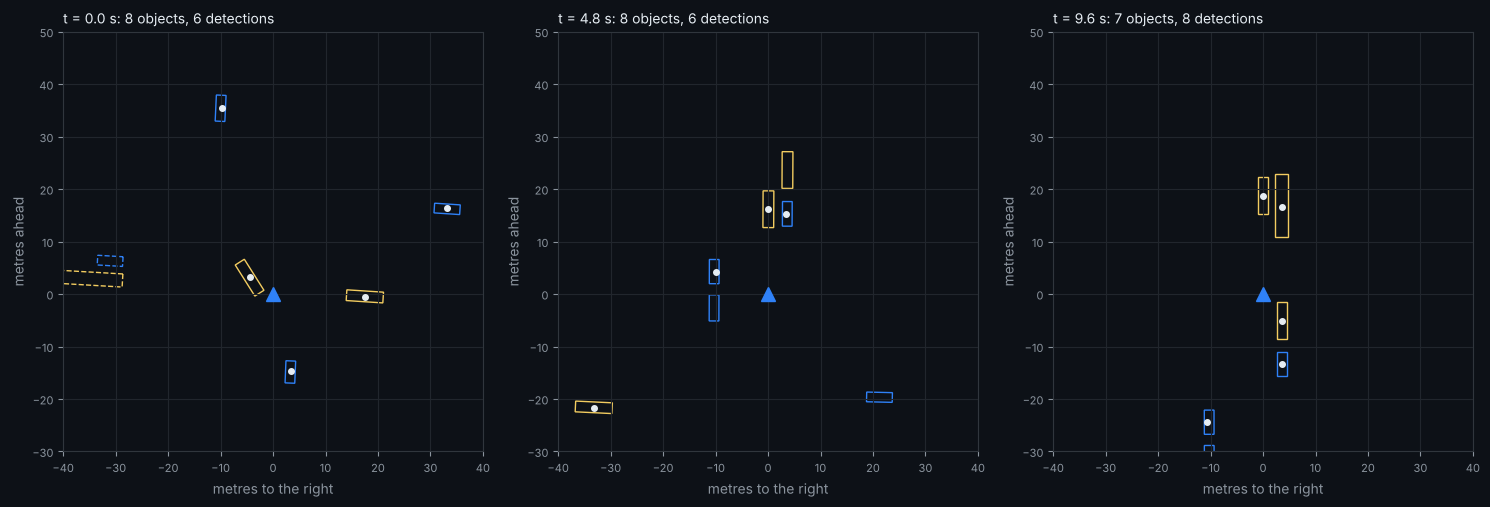

In [6]:
from matplotlib.patches import Polygon
plt.rcParams.update({"axes.titlecolor": "#e6edf3", "axes.labelcolor": "#8b949e"})
def dark(ax):
    ax.set_facecolor("#0d1117"); ax.tick_params(colors="#8b949e", labelsize=8); ax.grid(color="#21262d")
    for s in ax.spines.values(): s.set_color("#30363d")
    ax.title.set_color("#e6edf3"); ax.xaxis.label.set_color("#8b949e"); ax.yaxis.label.set_color("#8b949e")
fig, axs = plt.subplots(1, 3, figsize=(15, 5), facecolor="#0d1117")
for ax, k in zip(axs, np.linspace(0, len(samples) - 1, 3).astype(int)):
    sm = samples[k]
    for b in sm["boxes"]:
        c = box_corners(b["center"] + b["size"] + [b["yaw"]])[:4, :2]
        ax.add_patch(Polygon(c[:, ::-1] * [-1, 1], fill=False, ec=COL.get(b["class"], "w"), ls="--" if b["occluded"] else "-"))
    for d in sm["detections"]:
        x, y = d["center_ego_xy"]
        ax.plot(-y, x, "x" if d["class"] == "ghost" else "o", color="#f85149" if d["class"] == "ghost" else "#e6edf3", ms=4)
    ax.plot(0, 0, "^", color="#2f81f7", ms=10)
    ax.set_xlim(-40, 40); ax.set_ylim(-30, 50); ax.set_aspect("equal")
    ax.set_xlabel("metres to the right"); ax.set_ylabel("metres ahead")
    ax.set_title(f"t = {sm['timestamp_s']:.1f} s: {len(sm['boxes'])} objects, {len(sm['detections'])} detections", loc="left", fontsize=10); dark(ax)
fig.tight_layout(); display(fig); plt.close(fig)

## How good is the sensor here?

`xnet.perception.detect` is the sensor model behind the detections; its summary gives detection rates overall and on the long-tail
subsets (pedestrians and cyclists, objects that just emerged from behind an occluder, far objects). Run it with a stricter sensor
(fog, shorter range) on the same exported scene, no re-simulation needed.

In [7]:
from xnet import perception as PC
scene, meta = json.load(open(f"{OUT}/scene.json")), json.load(open(f"{OUT}/meta.json"))
ego = meta["ego_ids"][0]
for name, sensor in (("default", PC.Sensor()), ("fog 0.7", PC.Sensor(fog=0.7))):
    print(f"{name:8s}", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in PC.summary(PC.detect(scene, ego, sensor)).items()})

default  {'objects': 673, 'detected': 0.523, 'occluded_share': 0.256, 'vru_detected': 0.1, 'emerging_detected': 0.443, 'far_detected': 0.092, 'ghost_frames': 0, 'dropout_share': 0.0}
fog 0.7  {'objects': 673, 'detected': 0.287, 'occluded_share': 0.256, 'vru_detected': 0.0, 'emerging_detected': 0.205, 'far_detected': 0.013, 'ghost_frames': 0, 'dropout_share': 0.0}


## Loading it for training

A minimal dataset over the folder (plain numpy, wrap it in a `torch.utils.data.Dataset` as is). The same samples are in
`data.npz` in `bev.data`'s format, which `bev.train` trains the BEVFormer-style model on directly
([docs/BEV.md](../docs/BEV.md)).

In [8]:
class PerceptionFolder:
    def __init__(self, root):
        self.root, self.samples = root, json.load(open(f"{root}/samples.json"))
        self.cal = json.load(open(f"{root}/calibration.json"))
        self.cams = list(self.cal)
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, i):
        s = self.samples[i]
        imgs = np.stack([np.asarray(PILImage.open(f"{self.root}/{s['images'][c]}")) for c in self.cams])   # [6, H, W, 3]
        boxes = np.array([b["center"] + b["size"] + [b["yaw"]] + b["velocity"] for b in s["boxes"]], np.float32).reshape(-1, 9)
        return imgs, boxes, [b["class"] for b in s["boxes"]], np.stack([self.cal[c]["ego2img"] for c in self.cams])

ds = PerceptionFolder(OUT)
imgs, boxes, cls, ego2img = ds[0]
print(len(ds), imgs.shape, boxes.shape, cls[:5], ego2img.shape)

25 (6, 96, 176, 3) (8, 9) ['truck', 'car', 'truck', 'car', 'car'] (6, 4, 4)


## Many scenarios

Each export costs roughly 3 s per simulated second per ego on a CPU (rendering dominates). A dataset over every archetype:

```python
for name in famous.SCENARIOS:
    export.export(f"data/perception/{name}", area="chicago", scenario=name, seconds=20, egos=2)
```

Then RL on the same scenarios: `avrl.bench` has them as benchmark scenarios (`bench.SCENARIOS`), and notebook
[03](03_ppo_training.ipynb) shows how to train and score.